# Exercices 8

[Télécharger l'exercice](../08_exercice.zip)

# Exercice: Température de la croûte terrestre

Nous allons modéliser l'évolution du géotherme de la croûte terrestre en deux dimensions en incluant un paramètre d'exhumation et en simulant finalement une faille active dans un domaine modélisé de 50 km de longueur et de 25 km de profondeur (Figure 1). L'évolution du champ de température $T$ en 2D est le résultat de la diffusion thermique le long des axes $x$ et $z$, ainsi que de l'advection par exhumation, $\dot{e}$, le long d'une seule dimension ($z$) :

$$\frac{\partial T}{\partial t} = -\frac{\partial q_x}{\partial x} -\frac{\partial q_z}{\partial z}  - \dot{e} \frac{\partial T}{\partial z}\ ,\: $$

$$q_x = - D \frac{\partial T}{\partial x} \: ; \: \: q_z = - D \frac{\partial T}{\partial z}$$

La température initiale varie linéairement entre les valeurs données en surface et au fond du domaine modélisé. Tous les paramètres sont donnés dans la Table 1.

Puisque l'exhumation des roches s'effectue dans la seule direction $z$ (verticale), nous n'avons besoin de résoudre l'advection que dans la dimension $z$. Pour cela, il faut créer une matrice contenant les vitesses `Vz` de taille `(nz-1, nx)`. Ceci afin que les vitesses se situent à l'interface entre deux cellules de température "T", en analogie avec les flux.
 
![](./fig/ex_1.png)

*Figure: Le but de l'exercise est de modéliser le géotherme de la croûte terrestre avec deux taux d'exhumation différents.*

Deux dimensions compliquent aussi le calcul de `dt`, qui doit prendre en compte la valeur la plus petite d'entre les deux `dx` et `dz`, ainsi :

```python
dt = min(min(dx, dz)**2/(4.1*D), 0.01*dz/np.max(np.abs(Vz)))
```
Vous noterez que la valeur maximale de la matrice des vitesses `Vz` en valeure absolue est donnée par `np.max(np.abs(Vz))`. 

Nous voulons écrire un code avec deux variantes. Définissez un paramètre Q, qui vaut 1 ou 2, et utilisez des clauses conditionnelles pour écrire un unique code générique qui fonctionne pour les deux variantes.

- Q1: Dans une première version du code, la condition de température en profondeur est fixée à 700°C partout mais le taux d'exhumation change entre 5 km/Myr dans la partie gauche et 15 km/Myr dans la partie droite. Le flux de chaleur au travers des bords latéraux est nul. Le scénario tectonique équivalent serait la présence d'une faille normale séparant deux domaines s'érodant à des taux différents (Figure ci-dessus).  

- Q2: Dans une deuxième version du code, utilisez une condition limite de température $T$ en profondeur qui varie le long de l'axe $x$. La moitié gauche à 700°C et la droite à 900°C. La situation tectonique correspondante serait la subduction d'une croûte océanique froide sous la moitié gauche du modèle. Le flux de chaleur au travers des bords latéraux est également nul.  
 

| **Paramètres:**                                | **Valeurs:**                 |
|------------------------------------------------|------------------------------|
| Diffusivité de la température                  | 150 km²/Myr                 |
| Température à la surface                       | 25°C                        |
| Hauteur du modèle                              | 25 km                       |
| Largeur du modèle                              | 50 km                       |
| Nombre de cellules en x, $nx$                 | 50                           |
| Nombre de cellules en z, $nz$                 | 60                           |
| Temps total                                    | 10 Myr                      |
| **Q=1**                                |                              |
| T à 25 km de profondeur                        | 700°C                       |
| Taux d'exhumation entre 0 et 25 km            | 5 km/Myr                    |
| Taux d'exhumation entre 25 et 50 km           | 15 km/Myr                   |
| **Q=2**                                |                              |
| T à 25 km de profondeur entre $x = 0-25$ km  | 700°C                       |
| T à 25 km de profondeur entre $x = 25-50$ km | 900°C                       |
| Taux d'exhumation, $\dot{e}$                  | 10 km/Myr                   |

*Table 1: Paramètres du modèle.*

### ✅ **À vous de faire !** 

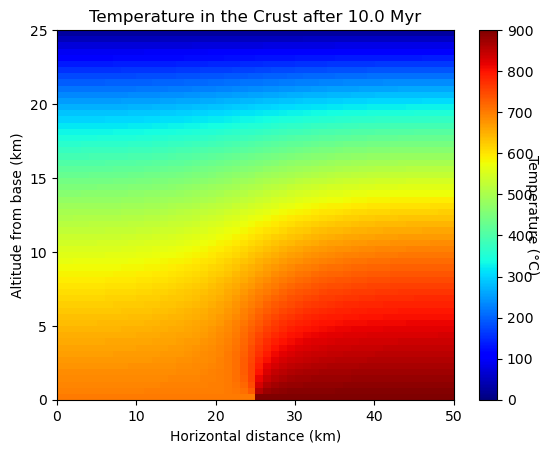

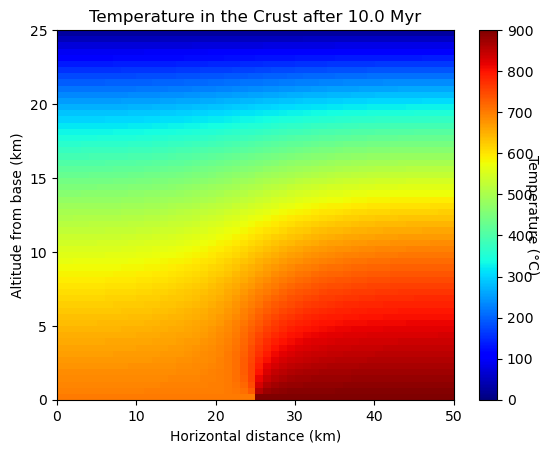

In [ ]:
import numpy as np
import matplotlib.pyplot as plt  
from IPython.display import display, clear_output

Q=2

# Physics
D = 150.0  # diffusivity, km^2/Myr
Lx = 50.0  # length along x, km
Lz = 25.0  # depth along y, km
ex_l = 5.0  # exhumation rate left,  km/Myr (b)
ex_r = 15.0  # exhumation rate right, km/Myr (b)
ex_t = 10.0  # exhumation rate right, km/Myr (a)
Ts = 25.0  # surface temperature, C
Tb = 700.0  # base temperature, C
Tb2 = 900.0  # base temperature, C (a)
tmax = 10.0  # maximum time, Myr
time = 0.0  # initial time

# Numerics
nx = 50  # number of x cells
nz = 60  # number of z cells
dx = Lx / (nx - 1)  # size of x-cell
dz = Lz / (nz - 1)  # size of z-cell
x = np.linspace(0, Lx, nx)  # x-coordinates
z = np.linspace(0, Lz, nz)  # z-coordinates
nout = 250  # frequency of plotting
it = 0  # initial timestep (because while loop)

X,Z = np.meshgrid(x,z) 

# Initialization
T = np.zeros((nz, nx))       # array for temperature 
Vz = np.zeros((nz - 1, nx))  # array for velocity

if Q==1:
    Vz[:,:int(nx / 2)] = ex_l   # exhumation rate on left
    Vz[:,int(nx / 2):] = ex_r    # exhumation rate on right
else:
    Vz[:] = ex_t                 # exhumation rate 
     
dt = min(min(dx, dz)**2/(4.1*D), 0.1*dz/np.max(np.abs(Vz)))  # time step

if Q==1:
   T = Tb + (Ts - Tb) * Z / Lz
else:
   T = ( Tb + (Ts - Tb) * Z / Lz ) * (X <= Lx/2) \
     + ( Tb2 + (Ts - Tb2) * Z / Lz ) * (X > Lx/2)
   
Tbase = np.copy(T[0,:])

fig, ax = plt.subplots()
s = ax.imshow(T, extent=[0, Lx, 0, Lz], origin='lower', cmap='jet',vmin=0,vmax=900)
cbar = plt.colorbar(s)
 
# Time loop
while time < tmax:

    # diffusion
    qz = -D * (T[1:, 1:-1] - T[:-1, 1:-1]) / dz  
    qx = -D * (T[1:-1, 1:] - T[1:-1, :-1]) / dx 
    dTdtd = - ( (qx[:,1:] - qx[:,:-1]) / dx + (qz[1:,:] - qz[:-1,:]) / dz )
    T[1:-1, 1:-1] += dTdtd * dt 
    
    # advection
    dTdta = - Vz * (T[1:,:] - T[:-1,:]) / dz  
    T[1:,:] += dTdta * dt 

    # boundary conditions
    T[:, 0] = T[:,1]  # no flux on edges
    T[:,-1] = T[:,-2] # no flux on edges
    T[-1,:] = Ts      # temperature at surface
    T[0,:]  = Tbase 

    it   += 1
    time += dt

    if it % nout == 0:

        clear_output(wait=True)  # Clear the output in VS Code
        ax.cla() 
        ax.imshow(T, extent=[0, Lx, 0, Lz], origin='lower', cmap='jet',vmin=0,vmax=900)
        plt.gca().set_aspect("auto") 
        cbar.set_label("Temperature (°C)", rotation=270)
        ax.set_xlabel('Horizontal distance (km)')
        ax.set_ylabel('Altitude from base (km)')
        ax.set_title(f'Temperature in the Crust after {round(time, 2)} Myr')
        display(fig)
        